<a href="https://colab.research.google.com/github/MuhamadAdityaa/ColabDeteksiGaris/blob/main/Pertemuan_6_ColabDeteksiGaris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Praktikum Pertemuan 6  
## Dasar Kecerdasan Buatan pada Robot: Persepsi & Visi Komputer

**Mata Kuliah:** Dasar Teknik Robotika dan Kecerdasan Buatan  
**Fokus Praktikum:** Kamera → Citra → Preprocessing → Edge → ROI → Hough Line → Interpretasi → Keputusan Robot

### Tujuan
Setelah menyelesaikan praktikum ini, mahasiswa mampu:
1. Mengambil citra menggunakan kamera laptop melalui Google Colab.
2. Menjelaskan perubahan citra pada tahap grayscale, Gaussian blur, Canny edge detection, dan ROI.
3. Mendeteksi garis menggunakan Probabilistic Hough Transform (`HoughLinesP`).
4. Menganalisis pengaruh parameter Canny dan Hough terhadap hasil deteksi.
5. Menginterpretasikan posisi garis menjadi keputusan sederhana robot: **LEFT, FORWARD, RIGHT, atau STOP**.

> **Catatan:** Praktikum menggunakan Google Colab agar tidak diperlukan instalasi Python, Jupyter, atau OpenCV secara lokal.



## Alur Praktikum

**Lingkungan → Kamera → Frame → Grayscale → Gaussian Blur → Canny → Region of Interest → Hough Line → Posisi Garis → Keputusan Robot**

Pada praktikum ini, motor robot belum dikendalikan secara fisik. Keputusan robot hanya **disimulasikan dalam bentuk teks dan visual**.


### Versi 2 — Perbaikan kompatibilitas HoughLinesP

Notebook ini memperbaiki pembacaan hasil `cv2.HoughLinesP()` agar tetap bekerja bila OpenCV
mengembalikan array dalam bentuk `(N,1,4)`, `(N,4)`, atau satu garis `(4,)`.
Fungsi kamera juga diberi fallback ke kamera default bila kamera belakang tidak tersedia.

In [ ]:
# 1. IMPORT LIBRARY
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

print("OpenCV version :", cv2.__version__)
print("Library siap digunakan.")

OpenCV version : 5.0.0
Library siap digunakan.



# Bagian A — Image Acquisition dengan Kamera Colab

Pada Jupyter lokal, webcam dapat dibuka menggunakan `cv2.VideoCapture(0)`.  
Pada Google Colab, Python berjalan pada runtime cloud sehingga kamera laptop diakses melalui **browser**.

Jalankan sel berikut, izinkan akses kamera, lalu tekan tombol **Capture**.


In [ ]:
# 2. FUNGSI CAPTURE KAMERA GOOGLE COLAB
def take_photo(filename="captured_photo.jpg", quality=0.90):
    js = Javascript(r"""
    async function takePhoto(quality) {
      const div = document.createElement('div');

      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.maxWidth = '720px';
      video.setAttribute('playsinline', '');

      const info = document.createElement('p');
      info.textContent = 'Arahkan kamera ke garis/lintasan, lalu tekan Capture.';

      const button = document.createElement('button');
      button.textContent = 'Capture';
      button.style.fontSize = '16px';
      button.style.padding = '8px 16px';
      button.style.margin = '8px 0';

      div.appendChild(info);
      div.appendChild(video);
      div.appendChild(button);
      document.body.appendChild(div);

      let stream;

      // Coba kamera belakang (umumnya ponsel/tablet).
      // Jika tidak tersedia, fallback ke kamera default laptop.
      try {
        stream = await navigator.mediaDevices.getUserMedia({
          video: { facingMode: { ideal: 'environment' } },
          audio: false
        });
      } catch (err) {
        stream = await navigator.mediaDevices.getUserMedia({
          video: true,
          audio: false
        });
      }

      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(
        document.documentElement.scrollHeight, true
      );

      await new Promise(resolve => button.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;

      const context = canvas.getContext('2d');
      context.drawImage(video, 0, 0, canvas.width, canvas.height);

      stream.getTracks().forEach(track => track.stop());
      div.remove();

      return canvas.toDataURL('image/jpeg', quality);
    }
    """)

    display(js)
    data = eval_js(f'takePhoto({quality})')

    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

print("Fungsi kamera siap.")

Fungsi kamera siap.


In [ ]:
# 3. AMBIL FOTO DARI KAMERA
# Browser akan meminta izin penggunaan kamera.
photo_file = take_photo()

img = cv2.imread(photo_file)

if img is None:
    raise ValueError("Foto tidak berhasil dibaca.")

print("Foto tersimpan :", photo_file)
print("Ukuran citra    :", img.shape)

<IPython.core.display.Javascript object>

Foto tersimpan : captured_photo.jpg
Ukuran citra    : (480, 640, 3)



### Alternatif jika kamera tidak dapat digunakan
Gunakan sel berikut untuk mengunggah gambar lintasan dari komputer.  
**Tidak perlu dijalankan jika kamera berhasil.**


In [ ]:
# 4. OPSIONAL — UPLOAD GAMBAR SEBAGAI CADANGAN
# Jalankan HANYA jika kamera tidak dapat digunakan.

# from google.colab import files
# uploaded = files.upload()
# filename = next(iter(uploaded))
# img = cv2.imread(filename)
# print("Gambar yang digunakan:", filename)
# print("Ukuran citra:", img.shape)

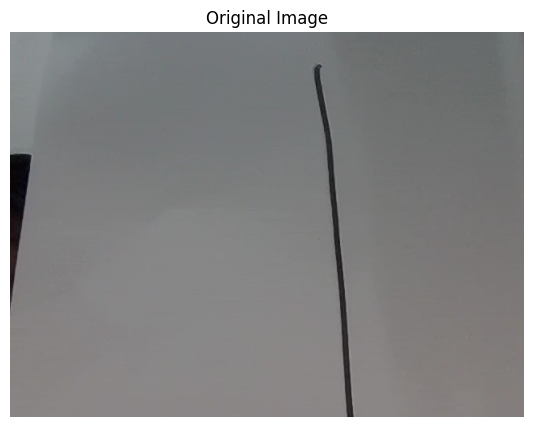

In [ ]:
# 5. FUNGSI UNTUK MENAMPILKAN CITRA
def show_image(image, title="Image", cmap=None, figsize=(8, 5)):
    plt.figure(figsize=figsize)

    if image.ndim == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    plt.title(title)
    plt.axis("off")
    plt.show()

show_image(img, "Original Image")


# Bagian B — Preprocessing

Tujuan preprocessing adalah mempersiapkan citra agar informasi penting lebih mudah ditemukan.

Tahapan yang digunakan:

1. **Grayscale** — mengubah citra menjadi satu kanal intensitas.
2. **Gaussian Blur** — mengurangi noise/detail kecil.
3. **Canny Edge Detection** — mencari perubahan intensitas yang kuat atau tepi.


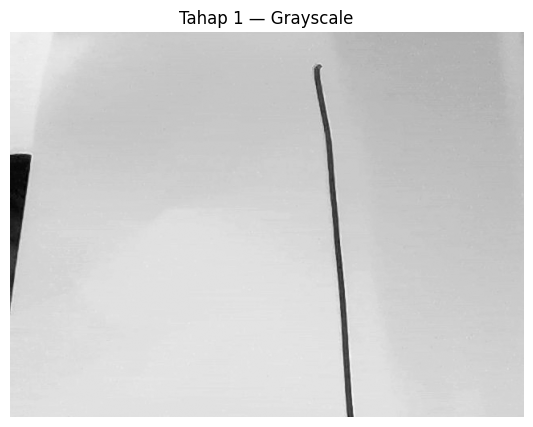

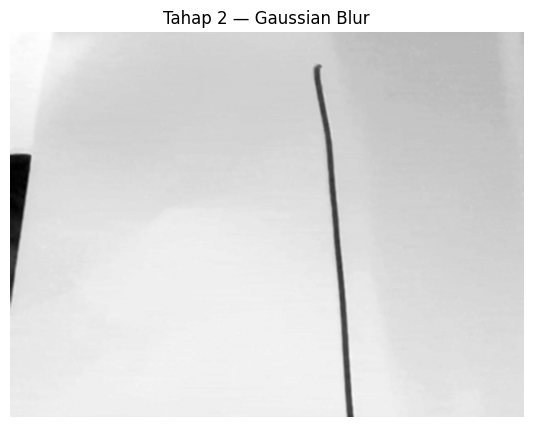

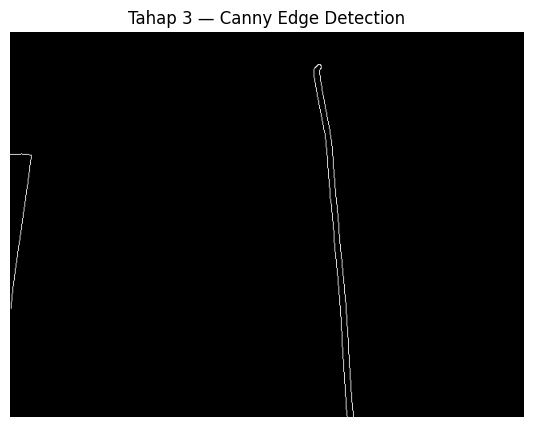

In [ ]:
# 6. PREPROCESSING DASAR

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

canny_lower = 50
canny_upper = 150

edges = cv2.Canny(blur, canny_lower, canny_upper)

show_image(gray, "Tahap 1 — Grayscale")
show_image(blur, "Tahap 2 — Gaussian Blur")
show_image(edges, "Tahap 3 — Canny Edge Detection")


## Pertanyaan Pengamatan 1
Amati citra asli, grayscale, blur, dan edge.

Diskusikan:
- Informasi apa yang hilang setelah citra menjadi grayscale?
- Mengapa Gaussian Blur diberikan sebelum Canny?
- Apakah semua edge yang terdeteksi merupakan bagian dari garis lintasan?



# Bagian C — Region of Interest (ROI)

Robot line follower tidak selalu membutuhkan seluruh bagian citra.

Pada contoh ini, hanya **bagian bawah citra** yang dianalisis karena lintasan yang relevan diasumsikan berada di depan robot.

Tujuan ROI:
- mengurangi objek pengganggu,
- memperkecil area pencarian,
- membuat deteksi lebih fokus.


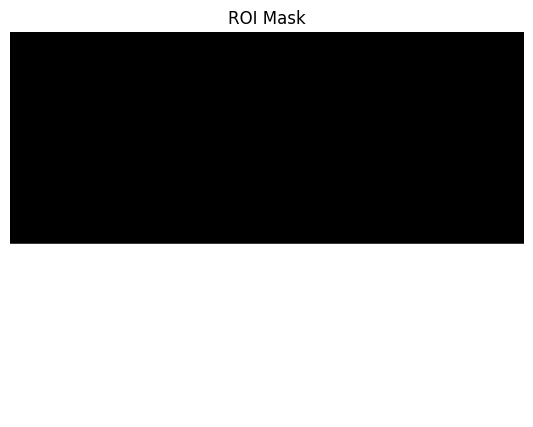

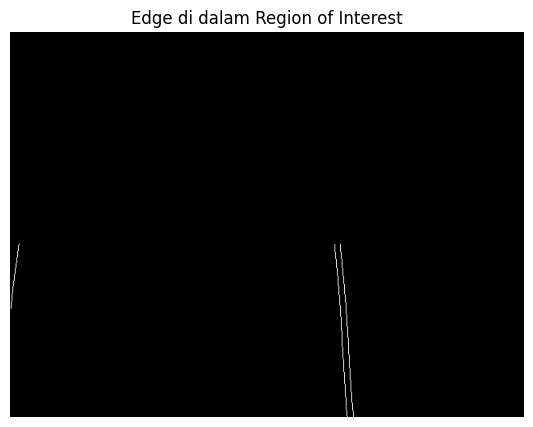

In [ ]:
# 7. FUNGSI REGION OF INTEREST

def apply_roi(edge_image, roi_top_ratio=0.55):
    h, w = edge_image.shape[:2]

    mask = np.zeros_like(edge_image)

    top_y = int(h * roi_top_ratio)

    polygon = np.array([[
        (0, h),
        (0, top_y),
        (w, top_y),
        (w, h)
    ]], dtype=np.int32)

    cv2.fillPoly(mask, polygon, 255)

    roi = cv2.bitwise_and(edge_image, mask)
    return roi, mask

roi, roi_mask = apply_roi(edges, roi_top_ratio=0.55)

show_image(roi_mask, "ROI Mask")
show_image(roi, "Edge di dalam Region of Interest")


## Pertanyaan Pengamatan 2

Bandingkan **Canny Edge seluruh citra** dengan **Edge di dalam ROI**.

- Edge mana yang hilang?
- Mengapa menghilangkan bagian citra tertentu dapat membantu robot?
- Apa risiko jika ROI dibuat terlalu sempit?



# Bagian D — Deteksi Garis dengan HoughLinesP

Setelah edge ditemukan, komputer masih hanya memiliki kumpulan pixel.

`HoughLinesP` digunakan untuk mencari kumpulan pixel yang konsisten membentuk **segmen garis**.

Output setiap garis:

`(x1, y1) → (x2, y2)`


In [ ]:
# 8. FUNGSI DETEKSI GARIS DAN INTERPRETASI POSISI

def detect_lines_and_decision(
    original,
    roi_edges,
    hough_threshold=50,
    min_line_length=50,
    max_line_gap=20,
    left_boundary=0.40,
    right_boundary=0.60
):
    result = original.copy()
    h, w = original.shape[:2]

    lines = cv2.HoughLinesP(
        roi_edges,
        rho=1,
        theta=np.pi / 180,
        threshold=hough_threshold,
        minLineLength=min_line_length,
        maxLineGap=max_line_gap
    )

    # Zona keputusan
    x_left = int(w * left_boundary)
    x_right = int(w * right_boundary)

    cv2.line(result, (x_left, 0), (x_left, h), (255, 0, 0), 2)
    cv2.line(result, (x_right, 0), (x_right, h), (255, 0, 0), 2)

    weighted_x = []
    weights = []

    # Normalisasi output HoughLinesP.
    # OpenCV umumnya menghasilkan (N,1,4), tetapi pada kondisi tertentu
    # bentuk array dapat berbeda. reshape(-1,4) membuat iterasi konsisten.
    if lines is not None and np.size(lines) >= 4:
        lines_array = np.asarray(lines).reshape(-1, 4)

        for x1, y1, x2, y2 in lines_array:
            # Ubah numpy.int32 menjadi int Python agar aman untuk OpenCV/math.
            x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))

            # Gambar garis hasil Hough
            cv2.line(result, (x1, y1), (x2, y2), (0, 255, 0), 3)

            # Titik tengah garis
            mid_x = (x1 + x2) / 2.0

            # Panjang garis sebagai bobot
            length = math.hypot(x2 - x1, y2 - y1)

            # Abaikan garis dengan panjang nol
            if length > 0:
                weighted_x.append(mid_x * length)
                weights.append(length)
    else:
        lines_array = np.empty((0, 4), dtype=np.int32)

    if len(weights) == 0:
        line_position = None
        zone = "NOT DETECTED"
        decision = "STOP / SEARCH LINE"

    else:
        line_position = sum(weighted_x) / sum(weights)

        if line_position < x_left:
            zone = "LEFT"
            decision = "TURN LEFT"

        elif line_position > x_right:
            zone = "RIGHT"
            decision = "TURN RIGHT"

        else:
            zone = "CENTER"
            decision = "GO FORWARD"

        cv2.circle(
            result,
            (int(line_position), int(h * 0.80)),
            12,
            (0, 0, 255),
            -1
        )

    text = f"ZONE: {zone} | DECISION: {decision}"
    cv2.putText(
        result,
        text,
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2,
        cv2.LINE_AA
    )

    number_of_lines = len(lines_array)

    return result, lines_array, line_position, zone, decision, number_of_lines

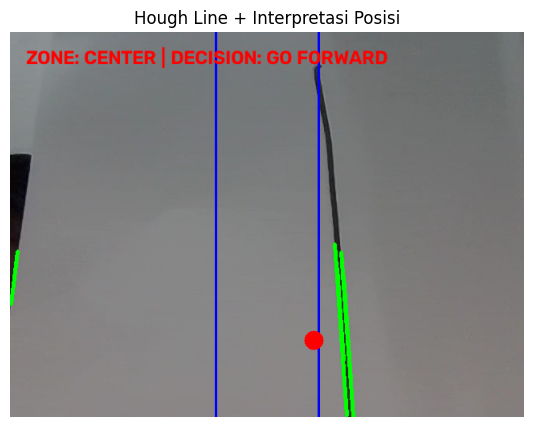

Jumlah garis terdeteksi : 5
Posisi estimasi garis   : 378.1785564512013
Zona                    : CENTER
Keputusan robot         : GO FORWARD


In [ ]:
# 9. JALANKAN HOUGH LINE + SIMULASI KEPUTUSAN ROBOT

result, lines, line_position, zone, decision, number_of_lines = \
    detect_lines_and_decision(
        img,
        roi,
        hough_threshold=50,
        min_line_length=50,
        max_line_gap=20
    )

show_image(result, "Hough Line + Interpretasi Posisi")

print("Jumlah garis terdeteksi :", number_of_lines)
print("Posisi estimasi garis   :", line_position)
print("Zona                    :", zone)
print("Keputusan robot         :", decision)


### Cara membaca hasil

- Garis **hijau** = segmen garis yang dideteksi Hough.
- Dua garis **biru** = batas zona LEFT–CENTER–RIGHT.
- Titik **merah** = estimasi posisi horizontal garis.
- Teks di atas citra = interpretasi sederhana untuk robot.

> Model keputusan ini bersifat **simulasi pembelajaran**, bukan kontrol robot line follower lengkap.



# Bagian E — Pipeline Lengkap dalam Satu Fungsi

Fungsi berikut menggabungkan seluruh tahapan sehingga parameter dapat diuji dengan lebih mudah.


In [ ]:
# 10. FUNGSI PIPELINE LENGKAP

def line_detection_pipeline(
    image,
    canny_lower=50,
    canny_upper=150,
    roi_top_ratio=0.55,
    hough_threshold=50,
    min_line_length=50,
    max_line_gap=20
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, canny_lower, canny_upper)

    roi, mask = apply_roi(edges, roi_top_ratio)

    result, lines, line_position, zone, decision, number_of_lines = \
        detect_lines_and_decision(
            image,
            roi,
            hough_threshold=hough_threshold,
            min_line_length=min_line_length,
            max_line_gap=max_line_gap
        )

    return {
        "gray": gray,
        "blur": blur,
        "edges": edges,
        "roi": roi,
        "result": result,
        "lines": lines,
        "line_position": line_position,
        "zone": zone,
        "decision": decision,
        "number_of_lines": number_of_lines,
        "edge_pixels": int(np.count_nonzero(edges))
    }


# Bagian F — Eksperimen Parameter

Bagian ini menggantikan **trackbar OpenCV** pada notebook lokal.

Di Google Colab, parameter dibuat sebagai **slider/form**.  
Ubah nilai parameter, lalu jalankan kembali sel berikut.


In [ ]:
# 11. PARAMETER EKSPERIMEN COLAB
# @title Parameter Canny dan Hough { run: "auto" }

canny_lower = 50       # @param {type:"slider", min:0, max:255, step:5}
canny_upper = 150      # @param {type:"slider", min:0, max:255, step:5}

roi_top_ratio = 0.55   # @param {type:"slider", min:0.30, max:0.85, step:0.05}

hough_threshold = 50   # @param {type:"slider", min:1, max:200, step:1}
min_line_length = 155   # @param {type:"slider", min:5, max:300, step:5}
max_line_gap = 20      # @param {type:"slider", min:0, max:150, step:5}

# Menjaga threshold Canny tetap logis
if canny_lower >= canny_upper:
    print("PERINGATAN: canny_lower sebaiknya lebih kecil dari canny_upper.")

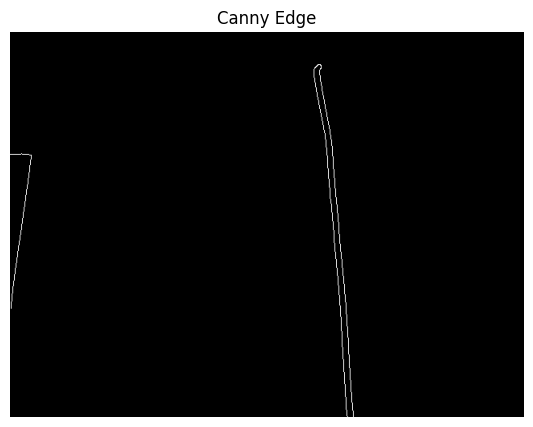

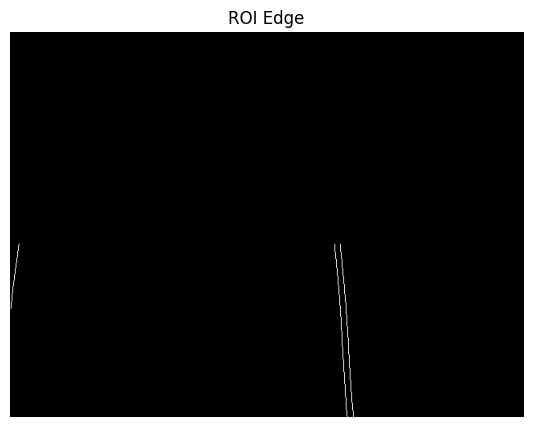

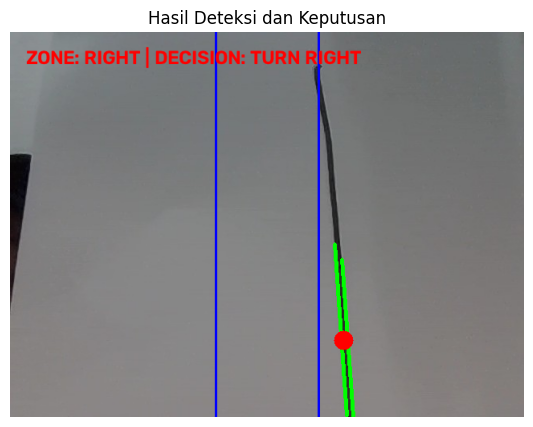

=== HASIL EKSPERIMEN ===
Edge pixels            : 1106
Jumlah garis Hough     : 2
Posisi estimasi garis  : 415.5636140064637
Zona                   : RIGHT
Keputusan              : TURN RIGHT


In [ ]:
# 12. JALANKAN PIPELINE DENGAN PARAMETER PILIHAN

exp_result = line_detection_pipeline(
    img,
    canny_lower=canny_lower,
    canny_upper=canny_upper,
    roi_top_ratio=roi_top_ratio,
    hough_threshold=hough_threshold,
    min_line_length=min_line_length,
    max_line_gap=max_line_gap
)

show_image(exp_result["edges"], "Canny Edge")
show_image(exp_result["roi"], "ROI Edge")
show_image(exp_result["result"], "Hasil Deteksi dan Keputusan")

print("=== HASIL EKSPERIMEN ===")
print("Edge pixels            :", exp_result["edge_pixels"])
print("Jumlah garis Hough     :", exp_result["number_of_lines"])
print("Posisi estimasi garis  :", exp_result["line_position"])
print("Zona                   :", exp_result["zone"])
print("Keputusan              :", exp_result["decision"])


## Aktivitas Eksperimen

Lakukan sedikitnya **3 konfigurasi parameter**.

Contoh:

| Percobaan | Canny Lower | Canny Upper | Hough Threshold | MinLineLength | MaxLineGap |
|---|---:|---:|---:|---:|---:|
| A | 30 | 80 | 30 | 30 | 10 |
| B | 50 | 150 | 50 | 50 | 20 |
| C | 100 | 200 | 80 | 80 | 40 |

Untuk setiap percobaan, catat:
- jumlah edge pixel,
- jumlah garis Hough,
- kualitas visual deteksi,
- zona garis,
- keputusan robot.

**Jangan hanya mencari parameter yang menghasilkan garis paling banyak.**  
Tujuannya adalah mencari hasil yang paling relevan dengan lintasan sebenarnya.


In [ ]:
# 13. CONTOH PERBANDINGAN OTOMATIS BEBERAPA KONFIGURASI

experiments = [
    {
        "Percobaan": "A",
        "canny_lower": 30,
        "canny_upper": 80,
        "hough_threshold": 30,
        "min_line_length": 30,
        "max_line_gap": 10
    },
    {
        "Percobaan": "B",
        "canny_lower": 50,
        "canny_upper": 150,
        "hough_threshold": 50,
        "min_line_length": 50,
        "max_line_gap": 20
    },
    {
        "Percobaan": "C",
        "canny_lower": 100,
        "canny_upper": 200,
        "hough_threshold": 80,
        "min_line_length": 80,
        "max_line_gap": 40
    }
]

records = []

for p in experiments:
    r = line_detection_pipeline(
        img,
        canny_lower=p["canny_lower"],
        canny_upper=p["canny_upper"],
        roi_top_ratio=0.55,
        hough_threshold=p["hough_threshold"],
        min_line_length=p["min_line_length"],
        max_line_gap=p["max_line_gap"]
    )

    records.append({
        "Percobaan": p["Percobaan"],
        "Canny Lower": p["canny_lower"],
        "Canny Upper": p["canny_upper"],
        "Hough Threshold": p["hough_threshold"],
        "MinLineLength": p["min_line_length"],
        "MaxLineGap": p["max_line_gap"],
        "Edge Pixels": r["edge_pixels"],
        "Detected Lines": r["number_of_lines"],
        "Zone": r["zone"],
        "Decision": r["decision"]
    })

comparison_df = pd.DataFrame(records)
comparison_df

,Percobaan,Canny Lower,Canny Upper,Hough Threshold,MinLineLength,MaxLineGap,Edge Pixels,Detected Lines,Zone,Decision
0,A,30,80,30,30,10,1107,5,CENTER,GO FORWARD
1,B,50,150,50,50,20,1106,5,CENTER,GO FORWARD
2,C,100,200,80,80,40,1101,2,RIGHT,TURN RIGHT



# Bagian G — Challenge Kamera

Ambil gambar baru menggunakan kamera dan lakukan pengujian berikut:

### Kondisi 1 — Garis di tengah
Prediksi keputusan robot sebelum menjalankan program.

### Kondisi 2 — Garis bergeser ke kiri
Amati apakah keputusan berubah.

### Kondisi 3 — Garis bergeser ke kanan
Amati apakah keputusan berubah.

### Kondisi 4 — Pencahayaan berubah
Bandingkan parameter terbaik pada cahaya terang dan cahaya lebih rendah.

### Kondisi 5 — Tambahkan objek pengganggu
Amati apakah ROI membantu mengurangi false detection.


<IPython.core.display.Javascript object>

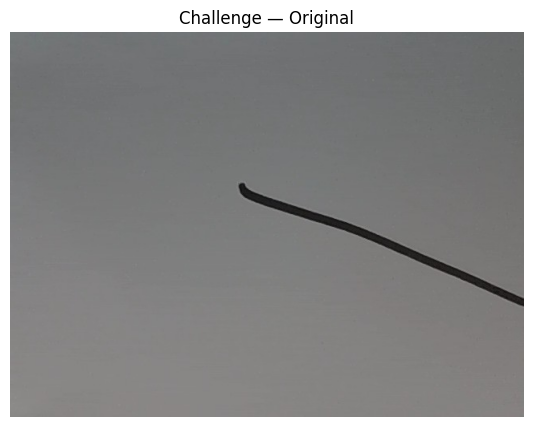

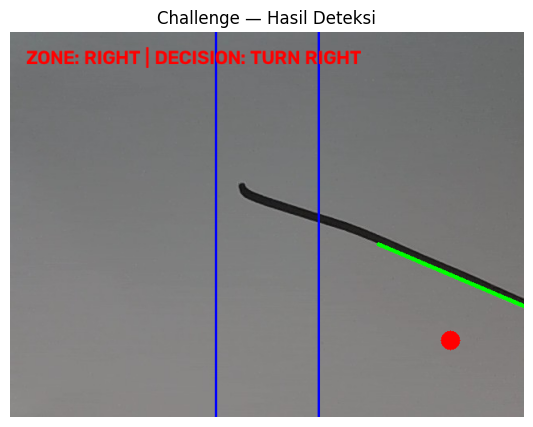

Zona      : RIGHT
Keputusan : TURN RIGHT
Garis     : 1


In [ ]:
# 14. CAPTURE ULANG UNTUK CHALLENGE
# Jalankan sel ini setiap kali ingin mengambil kondisi baru.

photo_file_2 = take_photo("challenge_photo.jpg")
img_challenge = cv2.imread(photo_file_2)

challenge = line_detection_pipeline(
    img_challenge,
    canny_lower=canny_lower,
    canny_upper=canny_upper,
    roi_top_ratio=roi_top_ratio,
    hough_threshold=hough_threshold,
    min_line_length=min_line_length,
    max_line_gap=max_line_gap
)

show_image(img_challenge, "Challenge — Original")
show_image(challenge["result"], "Challenge — Hasil Deteksi")

print("Zona      :", challenge["zone"])
print("Keputusan :", challenge["decision"])
print("Garis     :", challenge["number_of_lines"])


# Analisis C4 — Jawab Berdasarkan Hasil Eksperimen

1. Mengapa nilai Canny yang terlalu rendah dapat menghasilkan terlalu banyak edge?
2. Mengapa nilai Canny yang terlalu tinggi dapat menyebabkan sebagian lintasan tidak terdeteksi?
3. Apa pengaruh `minLineLength` terhadap jumlah garis yang diterima?
4. Apa pengaruh `maxLineGap` ketika garis/lintasan terputus?
5. Mengapa ROI dapat meningkatkan hasil deteksi?
6. Dalam kondisi apa ROI justru dapat menyebabkan kegagalan?
7. Jika hasil Hough mendeteksi banyak garis yang bukan lintasan, tahapan mana yang perlu diperbaiki?
8. Apakah konfigurasi parameter yang baik pada satu kondisi pencahayaan selalu baik pada kondisi lain? Jelaskan.
9. Bagaimana hasil persepsi visual diubah menjadi keputusan **LEFT / FORWARD / RIGHT**?
10. Apa keterbatasan keputusan berbasis aturan sederhana ini dibandingkan pendekatan AI/Machine Learning?



# Take Away Praktikum

- Kamera menghasilkan **data citra**, bukan pemahaman langsung tentang lingkungan.
- Preprocessing membantu menyiapkan citra sebelum informasi penting diekstraksi.
- Canny mendeteksi **edge**, sedangkan Hough menginterpretasikan kumpulan edge sebagai **garis**.
- ROI membantu robot memusatkan perhatian pada area yang relevan.
- Parameter sangat memengaruhi hasil; karena itu sistem vision harus **diuji pada kondisi nyata**.
- Hasil computer vision baru menjadi berguna bagi robot ketika diubah menjadi **informasi dan keputusan tindakan**.

**Pipeline utama:**

**Camera → Image → Preprocessing → Edge → ROI → Line → Interpretation → Decision**
